# **Lab Report: Leap Frog Method Assignment**
<h3 align="RIGHT">Submitted by: Kalyana Raama Bheema<h3>

# **Leapfrog Method: Electron Plasma Oscillation**

The leapfrog method solves equations of motion step by step. This method is used to get small errors at larger time steps.\
Consider a system whose motion is described by Newton's second law

$$\frac{d^2x}{dt^2} = a(x)$$

$a(x)$ is the acceleration, which depends on position.\
This is a second order differentila function so we can make this into two first order derivatives.\
$$\frac{dx}{dt} = v$$\
$$\frac{dv}{dt} = a(x)$$\
So, we can use leap frog method to solve this:\
In this method, Acceleration and position are in full steps, and Velocity is at half steps.\
$$v_{n+1/2} = v_{n-1/2} + \Delta t \cdot a(x_n)$$\
$$x_{n+1} = x_n + \Delta t \cdot v_{n + 1/2}$$\
Position and Acceleration jumps to full steps where velocity jumps at half steps, Thats why the name leap frog method.

> [**REF**](https://www.youtube.com/watch?v=pVudb6-_FaM)

## **Problem Statement:**

*   **Electron plasma oscillation**: An electron displaced from equilibrium in a uniform, fixed ion background feels an electric field
proportional to its displacement, and oscillates at the plasma frequency ωp. In normalized units
(ωp = 1), the motion is
$$\frac{dx}{dt} = v, \quad \frac{dv}{dt} = -\omega_p^2x, \quad \omega_p=1$$

$$x(0) = 0.5, \quad v(0) = 0, \quad 0 ≤t≤20$$


*   **Exact solution:**:

$$x(t) = 0.5cost,\quad v(t) = - 0.5sint$$


In [2]:
# do not change line below
#from google.colab import files

# import required packages here
import numpy as np
import matplotlib.pyplot as plt

## **Task 1: Leapfrog function**

In [4]:
wp = 1   # plasma frequency

def leapfrog(x, v, h):
    v = v - h * wp**2 * x   
    x = x + h * v          
    return x, v

## **Task 2: Initialize the half step**

$$v_{-1/2} = v_0 - \frac{h}{2}a(x_0), \quad a(x) = -\omega_p^2 x$$

In [10]:
x_0 = 0.5
v_0 = 0
h = 0.1

v_half = v_0 - h/2 * (-wp**2 * x_0)
print("v(-1/2) =", v_half)

v(-1/2) = 0.025


## **Task 3: Check the implementation ($h = 0.1$, $t = 20$)**

This function runs the leapfrog loop. After step $n$, $x$ is at time $nh$, but $v$ is at time $nh - h/2$.

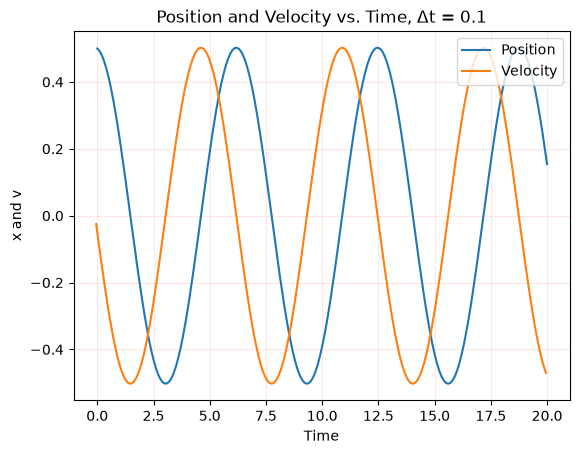

In [14]:
t = (0, 20)
v_i = v_0 - h/2 * wp* x_0

timestep = np.arange(t[0], t[1] + h/2, h)
n = len(timestep)

x, v = np.zeros_like(timestep), np.zeros_like(timestep)
x[0], v[0] = x_0, v_i
for i in range(1, n):
    x[i], v[i] = leapfrog(x[i-1], v[i-1], h)

plt.plot(timestep, x, label='Position')
plt.plot(timestep - h/2, v, label='Velocity')
plt.grid(True, color='r', alpha = 0.1)
plt.legend(loc='upper right')
plt.xlabel('Time')
plt.ylabel('x and v')
plt.title('Position and Velocity vs. Time, Δt = 0.1')
plt.show()

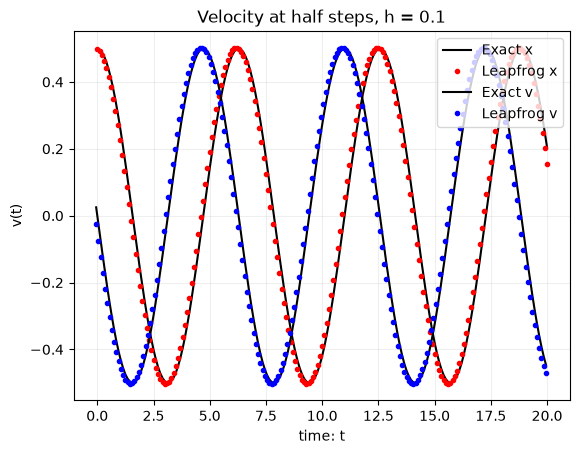

In [20]:
plt.plot(timestep, 0.5*np.cos(timestep), 'k', label='Exact x')
plt.plot(timestep, x, 'r.', label='Leapfrog x')
plt.xlabel('time: t')
plt.ylabel('x(t)')
plt.title('Position at whole steps, h = 0.1')
plt.plot(timestep - h/2, -0.5*np.sin(timestep - h/2), 'k', label='Exact v')
plt.plot(timestep - h/2, v, 'b.', label='Leapfrog v')
plt.xlabel('time: t')
plt.ylabel('v(t)')
plt.title('Velocity at half steps, h = 0.1')
plt.grid(True, alpha=0.2)
plt.legend(loc='upper right')
plt.show()

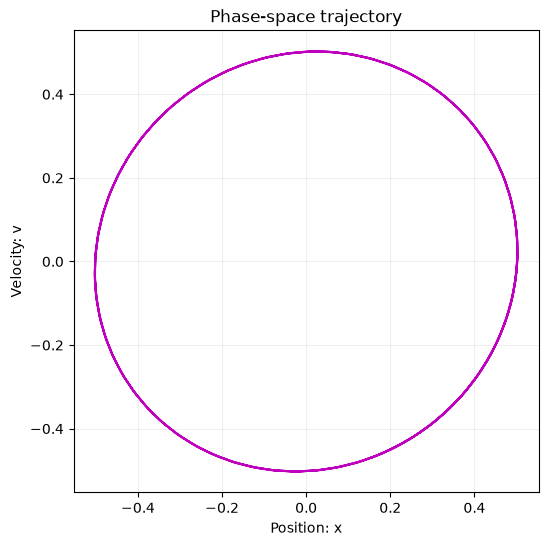

In [21]:
plt.figure(figsize=(6, 6))
plt.plot(x, v, 'm')
plt.xlabel('Position: x')
plt.ylabel('Velocity: v')
plt.title('Phase-space trajectory')
plt.grid(True, alpha=0.2)
plt.show()